# 03 · Segmentación de hogares: RFM y clustering

**Sesión 3 · Insights del consumidor y segmentación** (ruta Paid Media, semana 2: RFM y clustering con perfiles accionables).

Pregunta: ¿qué segmentación separa a los hogares que **después** valen distinto? Para el presupuesto de retención no basta con grupos bonitos: tienen que predecir el valor futuro.

- **Calibración** ene–sep 2017: variables y segmentos.
- **Validación** oct–dic 2017: η² = parte de la varianza del gasto futuro (log) y de la actividad que explica el segmento.

Usa Complete Journey (`data/interim`, requiere `python -m growth_lab.ingest`). Por licencia solo se publican los agregados: `segmentos_perfil` y `segmentos_comparacion`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from growth_lab import db, segmentacion as sg

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
con = db.conectar()
d = sg.variables_hogar(con)
comp, etiquetas = sg.comparar(d)
print(f"{len(d)} hogares con compras en la calibración; {d.activo_futuro.mean():.1%} compra en oct–dic")

2446 hogares con compras en la calibración; 94.2% compra en oct–dic


## 1. ¿Qué método predice mejor el valor futuro?

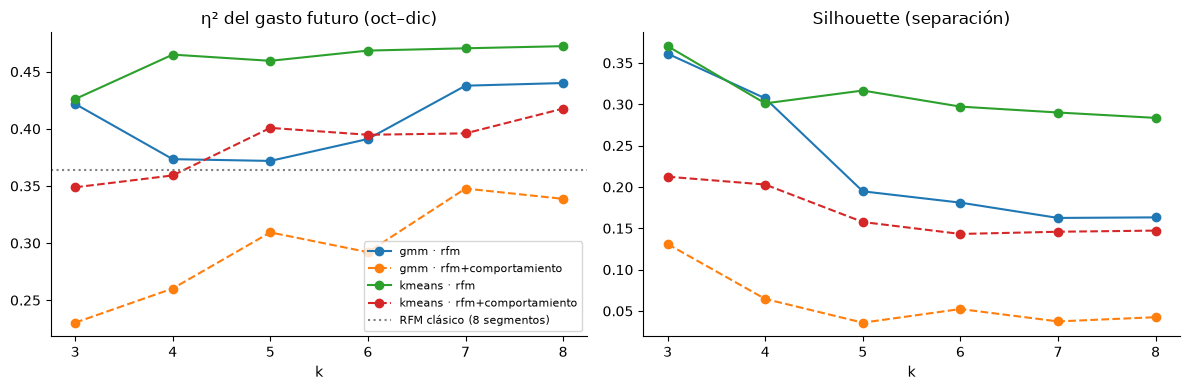

,metodo,variables,k,silhouette,bic,eta2_ventas_futuras,eta2_activo_futuro
0,rfm,rfm,8,NaN,NaN,0.364,0.085
1,kmeans,rfm,3,0.370,NaN,0.426,0.142
2,gmm,rfm,3,0.361,15519.686,0.422,0.148
3,kmeans,rfm,4,0.301,NaN,0.465,0.184
4,gmm,rfm,4,0.307,15492.943,0.373,0.150
5,kmeans,rfm,5,0.317,NaN,0.460,0.173
6,gmm,rfm,5,0.195,11574.805,0.372,0.169
7,kmeans,rfm,6,0.297,NaN,0.468,0.176
8,gmm,rfm,6,0.181,11575.702,0.391,0.177
9,kmeans,rfm,7,0.290,NaN,0.470,0.182


In [2]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
rfm = comp[comp.metodo == "rfm"].iloc[0]
for (metodo, variables), g in comp[comp.metodo != "rfm"].groupby(["metodo", "variables"]):
    estilo = "-" if variables == "rfm" else "--"
    a1.plot(g.k, g.eta2_ventas_futuras, estilo, marker="o", label=f"{metodo} · {variables}")
    a2.plot(g.k, g.silhouette, estilo, marker="o", label=f"{metodo} · {variables}")
a1.axhline(rfm.eta2_ventas_futuras, color="grey", ls=":", label="RFM clásico (8 segmentos)")
a1.set_title("η² del gasto futuro (oct–dic)"); a1.set_xlabel("k"); a1.legend(fontsize=8)
a2.set_title("Silhouette (separación)"); a2.set_xlabel("k")
fig.tight_layout(); plt.show()
comp.round(3)

## 2. Segmentación elegida: K-means RFM, k = 4 (decisión 003)

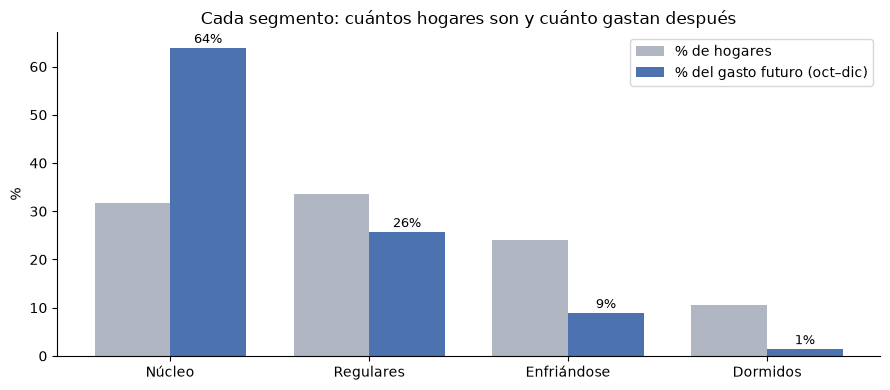

,hogares,recencia_dias,frecuencia,monto,ventas_futuras_media,pct_activo_futuro,pct_hogares,pct_ventas_futuras
segmento,,,,,,,,
Núcleo,778,2.0,80.0,2530.025,979.590,0.995,0.318,0.639
Regulares,820,5.0,33.0,875.580,374.071,0.988,0.335,0.257
Enfriándose,590,23.0,15.0,369.855,180.408,0.932,0.241,0.089
Dormidos,258,71.0,3.0,56.770,66.720,0.659,0.105,0.014


In [3]:
seg = sg.nombrar(d, etiquetas["kmeans|rfm|4"])
demo = con.sql("SELECT household_id, age, kids_count FROM cj_demographics").df()
perf = sg.perfil(d, seg, demo).set_index("segmento").loc[sg.NOMBRES_K4]

fig, ax = plt.subplots()
x = np.arange(len(perf)); w = 0.38
ax.bar(x - w/2, perf.pct_hogares * 100, w, label="% de hogares", color="#B0B7C3")
ax.bar(x + w/2, perf.pct_ventas_futuras * 100, w, label="% del gasto futuro (oct–dic)", color="#4C72B0")
for i, (h, v) in enumerate(zip(perf.pct_hogares, perf.pct_ventas_futuras)):
    ax.text(i + w/2, v * 100 + 1, f"{v:.0%}", ha="center", fontsize=9)
ax.set_xticks(x, perf.index); ax.set_ylabel("%"); ax.legend()
ax.set_title("Cada segmento: cuántos hogares son y cuánto gastan después")
fig.tight_layout(); fig.savefig("../docs/img/segmentos_valor.png", dpi=150); plt.show()
perf[["hogares", "recencia_dias", "frecuencia", "monto", "ventas_futuras_media", "pct_activo_futuro", "pct_hogares", "pct_ventas_futuras"]].round(3)

### Comportamiento: qué ofrecerle a cada segmento (solo describe, no segmenta)

In [4]:
perf[sg.VARIABLES_COMPORTAMIENTO + ["pct_con_demografia", "pct_con_hijos"]].round(3)

,ticket_medio,pct_desc_tienda,pct_cupon,pct_frescos,pct_drug_gm,pct_semanas_activas,pct_con_demografia,pct_con_hijos
segmento,,,,,,,,
Núcleo,29.994,0.141,0.003,0.237,0.110,0.897,0.650,0.340
Regulares,26.449,0.151,0.001,0.259,0.099,0.564,0.345,0.389
Enfriándose,24.774,0.152,0.000,0.255,0.097,0.308,0.020,NaN
Dormidos,16.238,0.140,0.000,0.213,0.072,0.077,0.000,NaN


## 3. ¿Es estable? Misma segmentación con 10 semillas distintas (índice de Rand ajustado)

In [5]:
x = sg.matriz(d, sg.VARIABLES_RFM)
base = KMeans(4, n_init=10, random_state=0).fit_predict(x)
ari = [adjusted_rand_score(base, KMeans(4, n_init=10, random_state=s).fit_predict(x)) for s in range(1, 11)]
print(f"ARI medio {np.mean(ari):.3f} (mín {np.min(ari):.3f}); 1 = idéntica")

ARI medio 0.952 (mín 0.898); 1 = idéntica


## 4. ¿A quién le llegaron las campañas? (insumo para la sesión 8)

Las campañas de Complete Journey no fueron aleatorias: si se concentraron en el Núcleo, comparar tratados contra no tratados sin ajustar exagera su efecto.

In [6]:
camp = con.sql("""SELECT c.household_id, d.campaign_type AS tipo FROM cj_campaigns c
JOIN cj_campaign_descriptions d USING (campaign_id)""").df()
canje = con.sql("SELECT DISTINCT household_id FROM cj_coupon_redemptions").df()
h = d[["household_id"]].assign(segmento=seg.values)
for t in ("Type A", "Type B", "Type C"):
    h[f"recibio_{t[-1]}"] = h.household_id.isin(camp[camp.tipo == t].household_id)
h["recibio_alguna"] = h.household_id.isin(camp.household_id)
h["canjeo_cupon"] = h.household_id.isin(canje.household_id)
expo = h.groupby("segmento")[[c for c in h if c.startswith(("recibio", "canjeo"))]].mean().loc[sg.NOMBRES_K4]
expo.round(3)

,recibio_A,recibio_B,recibio_C,recibio_alguna,canjeo_cupon
segmento,,,,,
Núcleo,0.963,0.808,0.392,0.972,0.382
Regulares,0.671,0.351,0.089,0.710,0.121
Enfriándose,0.310,0.129,0.032,0.358,0.024
Dormidos,0.027,0.008,0.000,0.035,0.000


## Mis conclusiones (Neider)

1. **Me quedo con K-means sobre RFM, k = 4.** Explica el 47% del gasto futuro frente al 36% del RFM clásico, y es estable (ARI 0,95 entre semillas).
2. **Más variables no es mejor:** el comportamiento baja el η² a 0,35–0,42. Lo uso para describir qué ofrecer, no para segmentar.
3. **El valor está muy concentrado:** el Núcleo es el 32% de los hogares y hace el 64% del gasto futuro; los Dormidos son el 11% y hacen el 1,4%.
4. **Mi apuesta de retención es Enfriándose:** 590 hogares; el 93% sigue comprando, pero con menos de la mitad de canastas que los Regulares (15 contra 33 en nueve meses). Lo valido con uplift (sesión 7) y con el efecto de las campañas (sesión 8).
5. **Las campañas no fueron al azar:** llegaron al 97% del Núcleo y solo al 36% de Enfriándose y al 3,5% de Dormidos. Comparar hogares con y sin campaña sin ajustar exageraría el efecto. Además, la demografía casi solo existe para el Núcleo (65% frente a 2% en Enfriándose), así que no sirve para perfilar a los que se enfrían.